### **Supervised Learning**

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from itertools import cycle

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    precision_score,
    recall_score,
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
)

### Logistic Regression

#### ლოგისტიკური რეგრესიის გამოყენების მაგალითები
მედიცინა → დაავადებების დიაგნოზი (დიაბეტი, კიბო, ინფექციები)  
ფინანსები → კრედიტის დამტკიცება (default vs. no default)  
მარკეტინგი → მომხმარებლის გადაწყვეტილების პროგნოზი (შეძენს თუ არა პროდუქტს?)  
სპორტი → მოგების შანსის გაანგარიშება  

- ლოგისტიკური რეგრესია პროგნოზირებს დისკრეტულ (0 ან 1) პასუხს (outcome)
- მოდელი იყენებს ლოგისტიკურ (sigmoid) ფუნქციას

ლოგისტიკური რეგრესიის ძირითადი განტოლებაა:  

$$P(Y=1 | X) = \sigma(z) = \frac{1}{1 + e^{-z}},$$ $$\quad z=a_0 + a_1X_1 + a_2X_2 + ... + a_nX_n,$$

სადაც: 
- $P(Y=1 | X)$ — ალბათობა იმისა, რომ შედეგი 1 იყოს.  
- $a_0$ — Intercept (მოდელის საწყისი მნიშვნელობა).  
- $a_1, a_2, ..., a_n$ — კოეფიციენტები, რომლებიც განსაზღვრავენ გავლენას ცვლადებზე.  
- $X_1, X_2, ..., X_n$ — დამოუკიდებელი ცვლადები.  
- $e$ — ბუნებრივი ლოგარითმის ბაზა (~2.718).  

#### ლოგისტიკური რეგრესია: ლოკალური მინიმუმები არ აქვს, მაგრამ შეიძლება ჰქონდეს პლატოები და ნელი კონვერგენცია

* ლოგისტიკური რეგრესიის cost function კონვექსურია, ამიტომ ლოკალური მინიმუმების პრობლემა არ გვაქვს
* თუმცა cost function-ს შეიძლება ჰქონდეს ბრტყელი რეგიონები, ანუ პლატოები
* ასეთ ადგილებში გრადიენტი ძალიან მცირე ხდება და Gradient Descent მხოლოდ პატარა ნაბიჯებს დგამს
* ცუდად დასქეილებული feature-ები კიდევ უფრო ანელებს კონვერგენციას

→ ამიტომ Feature Scaling / ნორმალიზაცია ძალიან რეკომენდებულია

### Iris flower data set with one feature

In [3]:
# Load Data: Seaborn Iris (drop virginica, keep one feature)
df = sns.load_dataset("iris")
df_iris = (
    df.query("species != 'virginica'")
           .reset_index(drop=True)[["sepal_length", "species"]]
)
df_iris.head()

,sepal_length,species
0,5.1,setosa
1,4.9,setosa
2,4.7,setosa
3,4.6,setosa
4,5.0,setosa


In [4]:
# Binary target: setosa=0, versicolor=1
X = df_iris[["sepal_length"]]
y = (df_iris["species"] == "versicolor").astype(int)

In [5]:
# განვსაზღვროთ და გავწრთვნათ Logistic Regression მოდელი
clf = LogisticRegression(random_state=42)
clf.fit(X, y)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [6]:
# Model stats
print("coef (a):", clf.coef_.round(2)[0, 0])
print("intercept (b):", clf.intercept_.round(2)[0])

coef (a): 3.18
intercept (b): -17.25


$$P(Y=1 | X) = \frac{1}{1 + e^{-z}},$$ $$\quad z=3.18 * X_1 -17.24.$$

In [7]:
# z = a*X_1 + b
logits = clf.decision_function(X)
print("Logits (z):", logits[:5])  # პირველი 5-ის ჩვენება

# პროგნოზის ალბათობები (sigmoid(z))
probs = clf.predict_proba(X)
print("Probabilities (p=1):", probs[:5, 1])  # პირველ 5-ის ალბათობა

pred = clf.predict(X)[:5]
print("Output:", pred[:5])  # პირველ 5-ის პროგნოზი

Logits (z): [-1.04908243 -1.68424008 -2.31939773 -2.63697656 -1.36666125]
Probabilities (p=1): [0.25940134 0.15653483 0.08952914 0.06679625 0.20315981]
Output: [0 0 0 0 0]


Decision boundary at $P=0.5$, 
$$P=\frac{1}{2}=\frac{1}{1 + e^0},$$ $$z=0 → a*x + b = 0 → x = -b/a = 5.43.$$

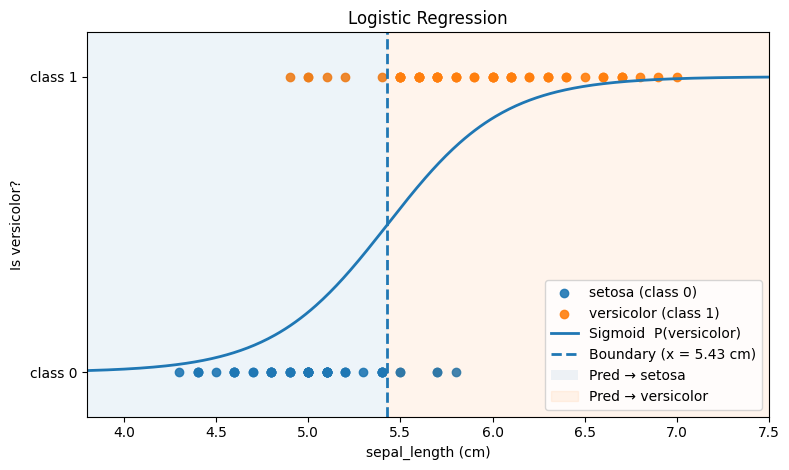

In [8]:
# Build smooth grid for sigmoid curve
x_min, x_max = X["sepal_length"].min() - 0.5, X["sepal_length"].max() + 0.5
x_grid = np.linspace(x_min, x_max, 400).reshape(-1, 1)
proba = clf.predict_proba(x_grid)[:, 1]  # P(class 1 = versicolor)

# Decision boundary at P=0.5 → a*x + b = 0 → x = -b/a
a = clf.coef_[0, 0]
b = clf.intercept_[0]
x_star = -b / a

plt.figure(figsize=(8, 4.8))
plt.scatter(X[y == 0]["sepal_length"], y[y == 0], alpha=0.9, label="setosa (class 0)")
plt.scatter(X[y == 1]["sepal_length"], y[y == 1], alpha=0.9, label="versicolor (class 1)")
plt.plot(x_grid.ravel(), proba, linewidth=2, label="Sigmoid  P(versicolor)")
plt.axvline(x_star, linestyle="--", linewidth=2, label=f"Boundary (x = {x_star:.2f} cm)")
plt.axvspan(x_min, x_star, alpha=0.08, label="Pred → setosa")
plt.axvspan(x_star, x_max, alpha=0.08, label="Pred → versicolor", color="C1")
plt.ylim(-0.15, 1.15)
plt.xlim(x_min, x_max)
plt.yticks([0, 1], ["class 0", "class 1"])
plt.xlabel("sepal_length (cm)")
plt.ylabel("Is versicolor?")
plt.title("Logistic Regression")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [9]:
# Missclassified points
y_pred = clf.predict(X)
pd.concat([
    df_iris[y != y_pred].reset_index(drop=True),
    pd.Series(y_pred[y != y_pred], name="prediction").map({1: "versicolor", 0: "setosa"})
], axis=1)

,sepal_length,species,prediction
0,5.8,setosa,versicolor
1,5.7,setosa,versicolor
2,5.7,setosa,versicolor
3,5.5,setosa,versicolor
4,5.5,setosa,versicolor
5,4.9,versicolor,setosa
6,5.2,versicolor,setosa
7,5.0,versicolor,setosa
8,5.4,versicolor,setosa
9,5.0,versicolor,setosa


### Iris flower data set with 2 Features

In [10]:
df_iris = (
    df.query("species != 'virginica'")
           .reset_index(drop=True)[["sepal_length", "sepal_width", "species"]]
)
df_iris.head()

,sepal_length,sepal_width,species
0,5.1,3.5,setosa
1,4.9,3.0,setosa
2,4.7,3.2,setosa
3,4.6,3.1,setosa
4,5.0,3.6,setosa


In [11]:
# Binary target: setosa=0, versicolor=1
X = df_iris.drop("species", axis=1)
y = (df_iris["species"] == "versicolor").astype(int)

In [12]:
# Logistic Regression
clf = LogisticRegression(random_state=42)
clf.fit(X, y)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [13]:
# Model stats
print("coefs (a1, a2):", clf.coef_.round(2)[0])
print("intercept (b):", clf.intercept_.round(2)[0])

coefs (a1, a2): [ 3.08 -3.02]
intercept (b): -7.34


$$P(Y=1 | X) = \frac{1}{1 + e^{-z}},$$ $$\quad z=3.08 * X_1 - 3.02 * X_2 -7.34.$$

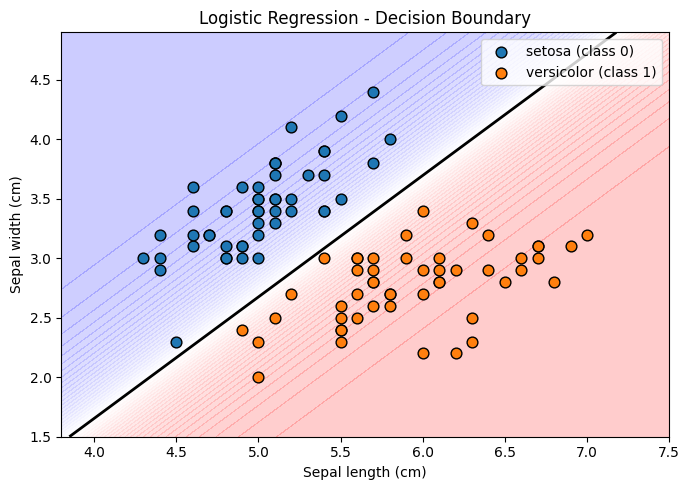

In [14]:
# Grid for decision boundary
x_min, x_max = X["sepal_length"].min() - 0.5, X["sepal_length"].max() + 0.5
y_min, y_max = X["sepal_width"].min() - 0.5, X["sepal_width"].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
proba = clf.predict_proba(grid)[:, 1].reshape(xx.shape)


plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, proba, levels=50, cmap="bwr", alpha=0.2)
plt.contour(xx, yy, proba, levels=[0.5], colors="black", linewidths=2)
plt.scatter(
    X["sepal_length"][y == 0],
    X["sepal_width"][y == 0],
    color="C0", label="setosa (class 0)", edgecolor="k", s=60
)
plt.scatter(
    X["sepal_length"][y == 1],
    X["sepal_width"][y == 1],
    color="C1", label="versicolor (class 1)", edgecolor="k", s=60
)
plt.xlabel("Sepal length (cm)")
plt.ylabel("Sepal width (cm)")
plt.title("Logistic Regression - Decision Boundary")
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
# Missclassified points
y_pred = clf.predict(X)
pd.concat([
    df_iris[y != y_pred].reset_index(drop=True),
    pd.Series(y_pred[y != y_pred], name="prediction").map({1: "versicolor", 0: "setosa"})
], axis=1)

,sepal_length,sepal_width,species,prediction


### **მოდელის ევალუაცია**

#### Confusion Matrix
კლასიფიკაციის მოდელების შეფასებისთვის ხშირად ვიყენებთ Confusion Matrix-ს. Confusion Matrix არის ცხრილი, რომელიც გვიჩვენებს, თუ რამდენად კარგად პროგნოზირებს მოდელი რეალურ მნიშვნელობებთან შედარებით.

|   | Actual Positive (1) | Actual Negative (0) |
|---|--------------------|--------------------|
| Predicted Positive (1) | ✓ True Positive (TP) | ✗ False Positive (FP) |
| Predicted Negative (0) | ✗ False Negative (FN) | ✓ True Negative (TN) |

მნიშვნელობები:  
- True Positive (TP) → მოდელმა სწორად იწინასწარმეტყველა პოზიტიური შემთხვევა.  
- False Positive (FP) → მოდელმა შეცდომით იწინასწარმეტყველა პოზიტიური, რეალურად უარყოფითია.  
- False Negative (FN) →  მოდელმა შეცდომით იწინასწარმეტყველა უარყოფითი, რეალურად პოზიტიურია. 
- True Negative (TN) → მოდელმა სწორად იწინასწარმეტყველა უარყოფითი შემთხვევა. 

#### ძირითადი მეტრიკები

#### Precision (სიზუსტე)
გვიჩვენებს, მოდელის მიერ პროგნოზირებული რამდენი დადებითი შემთხვევაა რეალურად დადებითი.  

$\text{Precision} = \frac{TP}{TP + FP}$

- მაღალი Precision → მოდელი იშვიათად უშვებს ცრუ დადებით (False Positive (FP)) შეცდომებს.  
- დაბალი Precision → ბევრი ცრუ დადებითი (False Positive (FP)) შემთხვევაა.  

მაგალითი: სპამის ფილტრაციის მოდელისათვის მაღალი Precision ნიშნავს, რომ მოდელი მხოლოდ ნამდვილად სპამ წერილებს ფილტრავს.  

---

#### Recall (მგრძნობელობა)
გვიჩვენებს, რამდენი რეალური დადებითი შემთხვევა აღმოაჩინა მოდელმა.  

$\text{Recall} = \frac{TP}{TP + FN}$

- მაღალი Recall → მოდელი იშვიათად უშვებს ცრუ უარყოფით (False Negative (FN)) შეცდომებს.  
- დაბალი Recall → ბევრი ცრუ უარყოფითი (False Negative (FN)) შემთხვევაა.  

მაგალითი: კიბოს დიაგნოზში Recall მაღალი უნდა იყოს, რათა არ გამოვტოვოთ რეალური ავადმყოფები.  


#### Accuracy (სიზუსტე)
მოდელის საერთო სიზუსტე, რამდენად სწორია მისი ყველა პროგნოზი.  

$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$

- გამოიყენება, როცა კლასები ბალანსირებულია.  
- თუ მონაცემები არაბალანსირებულია, Accuracy მეტრიკამ შეიძლება შეცდომაში შეგიყვანოს.  

მაგალითი: თუ 95% პაციენტებს არ აქვთ კიბო, მაშინ მოდელი, რომელიც ყოველთვის ამბობს "არ არის კიბო", იქნება 95% ზუსტი, მაგრამ უსარგებლო.

---

#### F1-Score (Precision და Recall-ის კომბინაცია)

$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$

- გამოიყენება, როცა საჭიროა Precision და Recall-ის ბალანსი.  

მაგალითი: თაღლითობის გამოვლენის მოდელში გვინდა ბალანსი Precision-სა და Recall-ს შორის, რათა არც ბევრი ცრუ დადებითი (False Positive (FP)) გვქონდეს და არც ბევრი გამორჩენილი (False Negative (FN)) თაღლითობა.

---

In [16]:
# ვთქვათ გვაქვს შემდეგი მონაცემები
y_actual = [1, 0, 1, 1, 0, 1, 0, 0, 1, 0]  # ნამდვილი მნიშვნელობები
y_predic = [1, 0, 1, 0, 0, 1, 0, 1, 1, 0]  # მოდელის პროგნოზები

# Confusion Matrix
tn, fp, fn, tp = confusion_matrix(y_actual, y_predic).ravel()

# მეტრიკების გამოთვლა
precision = precision_score(y_actual, y_predic)
recall = recall_score(y_actual, y_predic)
accuracy = accuracy_score(y_actual, y_predic)
f1 = f1_score(y_actual, y_predic)

print(f"True Positives (TP): {tp}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Negatives (TN): {tn}\n")

print(f"Precision: {precision:.2f}") # TP / (TP + FP)
print(f"Recall: {recall:.2f}") # TP / (TP + FN)
print(f"Accuracy: {accuracy:.2f}") # (TP + TN) / (TP + TN + FP + FN)
print(f"F1-Score: {f1:.2f}\n") # 2 * (Precision * Recall) / (Precision + Recall)

True Positives (TP): 4
False Positives (FP): 1
False Negatives (FN): 1
True Negatives (TN): 4

Precision: 0.80
Recall: 0.80
Accuracy: 0.80
F1-Score: 0.80



threshold არის ალბათობის ზღვარი, რომელსაც მოდელი იყენებს იმისთვის, რომ განსაზღვროს ნიმუში რომელ კლასს ეკუთვნის.

ლოგისტიკური რეგრესია პირდაპირ კლასს არ გვიბრუნებს.
ის აბრუნებს ალბათობას ((0-1) დიაპაზონი).

* probability ≥ 0.5 → პროგნოზი პოზიტიური (class=1)
* probability < 0.5 → პროგნოზი ნეგატიური (class=0)


| Probability | Threshold | Prediction |
| ----------- | --------- | ---------- |
| 0.73        | 0.5       | Positive   |
| 0.42        | 0.5       | Negative   |

ROC მრუდის იდეა:

threshold-ს ვცვლით 0-დან 1-მდე და ვაკვირდებით, როგორ იცვლება მოდელის ქცევა.

threshold ცვლის ბალანსს True Positive, False Positive, True Negative, False Negative მნიშვნელობებში. შესაბამისად იცვლება TPR და FPR.

#### ROC-AUC 
ROC-AUC არის კლასიფიკაციის მოდელის ხარისხის საზომი, რომელიც აჩვენებს ნამდვილი დადებითი მაჩვენებლის (True Positive Rate, TPR) და ცრუ დადებითი მაჩვენებლის (False Positive Rate, FPR) ურთიერთობას.

- ROC Curve (Receiver Operating Characteristic) → აჩვენებს TPR vs. FPR, სხვადასხვა Decision Threshold-ისთვის.
- AUC (Area Under the Curve) → ამ მრუდის ქვეშ არსებული ფართობი (0 - 1 შორის).
  - AUC = 1.0 → იდეალური მოდელი.
  - AUC = 0.5 → შემთხვევითი ვარაუდი.
  - AUC < 0.5 → ცუდი მოდელი.
---

როგორ ითვლება?
1. TPR (Recall, Sensitivity)

   $TPR = \frac{TP}{TP + FN}$

   
   (რეალური დადებითი შემთხვევებიდან რა ნაწილი იქნა სწორად კლასიფიცირებული)
   
2. FPR (False Positive Rate)

   
   $FPR = \frac{FP}{FP + TN}$

   
   (უარყოფითი შემთხვევებიდან რა ნაწილი კლასიფიცირდა შეცდომით, ისე როგორც დადებითი)

3. ROC მრუდის აგება 
   - სხვადასხვა Threshold-ისთვის (0-დან 1-მდე) გამოითვლება TPR და FPR.
   - ამ წერტილებით ვხატავთ ROC Curve-ს.

4. AUC გამოთვლა  
   - რაც უფრო მაღალია AUC, მით უკეთესია მოდელი!
   - AUC Score > 0.8 → ძლიერი მოდელია!  
   - რაც უფრო მაღალია AUC, მით უკეთესია მოდელი უარყოფითისა და დადებითის გარჩევაში.

| <img src="../../images/roc_auc.png" alt="Image 1" width="700"> | <img src="../../images/roc-curve-v2.png" alt="Image 2" width="600"> |
|---------------------------------------------------------|---------------------------------------------------------|

```
FPR = [0.0, 0.05, 0.10, 1.0]
TPR = [0.0, 0.60, 0.90, 1.0]
thresholds = [inf, 0.83, 0.45, 0.10]
```
რატომ გადადის TPR და FPR მნიშვნელობა 0-დან 1-მდე?

| Threshold | პროგნოზი                  | შედეგი                 |
| --------- | ------------------------- | ---------------------- |
| ∞         | არცერთი ნიმუში არ ინიშნება პოზიტიურად | TPR=0, FPR=0           |
| მაღალი    | რამდენიმე პოზიტიური       | მცირე TPR, მცირე FPR   |
| საშუალო   | მეტი პოზიტიური            | უფრო მაღალი TPR და FPR |
| დაბალი    | თითქმის ყველა პოზიტიური   | TPR=1, FPR=1           |
| 0         | ყველა ინიშნება პოზიტიურად  | TPR=1, FPR=1           |
----
#### განსხვავება Precision-Recall Curve და ROC-AUC შორის

Precision-Recall Curve (PR Curve) და ROC-AUC Curve ორივე არის კლასიფიკაციის მოდელის შეფასების მეთოდები, მაგრამ ისინი განსხვავებულად აფასებენ მოდელის მუშაობას.

| კრიტერიუმი | ROC-AUC | Precision-Recall (PR) AUC |
|--------------|------------|------------------------------|
| X-ღერძი | FPR (False Positive Rate) | Recall (Sensitivity) |
| Y-ღერძი | TPR (True Positive Rate) | Precision (PPV) |
| სად გამოვიყენოთ? | ბალანსირებული მონაცემები | არაბალანსირებული მონაცემები |
| რას ზომავს? | მოდელის ზოგად სიზუსტეს | რამდენად ზუსტად ამოიცნობს მოდელი პოზიტიურ შემთხვევებს |
| საუკეთესო შედეგი | 1.0 | 1.0 |

---

რომელ სიტუაციაში რომელი უნდა გამოვიყენოთ?
| პრობლემა | საუკეთესო შეფასება |
|------------|------------------------------|
| Spam-ფილტრი (50% Spam, 50% არა-Spam) | ROC-AUC |
| სამედიცინო დიაგნოზი (1% დაავადება, 99% ჯანმრთელი) | PR-AUC |
| თაღლითობის აღმოჩენა (2% თაღლითური, 98% ნორმალური ოპერაცია) | PR-AUC |
| კომენტარების პოზიტიურობა (50% დადებითი, 50% უარყოფითი) | ROC-AUC |

---

In [17]:
y_actual = [1, 0, 1, 1, 0, 1, 0, 0, 1, 0]  # ნამდვილი მნიშვნელობები
y_predic = [1, 0, 1, 0, 0, 1, 0, 1, 1, 0]  # მოდელის პროგნოზები

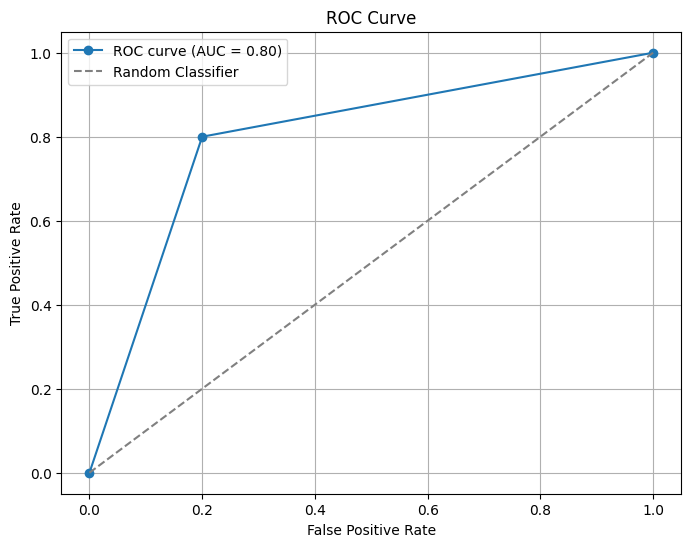

In [18]:
# ROC Curve
fpr, tpr, thresholds = roc_curve(y_actual, y_predic)
auc_value = roc_auc_score(y_actual, y_predic)

# ROC კერვის ნახატის შექმნა
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, marker='o', label=f'ROC curve (AUC = {auc_value:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(True)
plt.show()

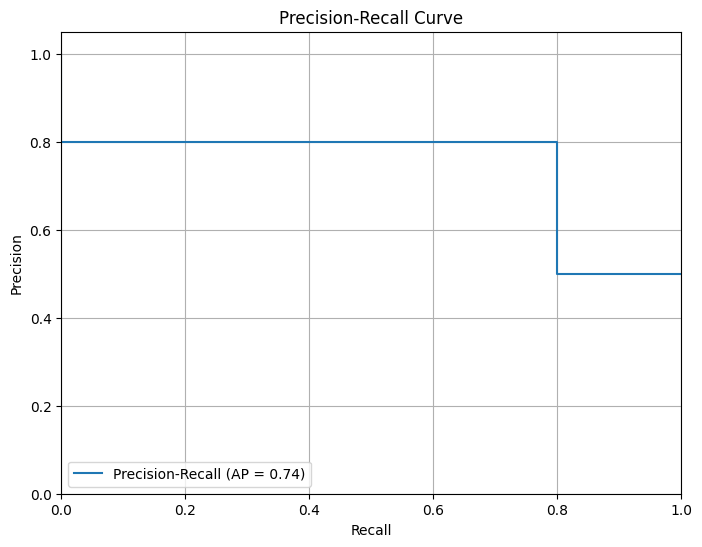

In [19]:
# Precision-Recall Curve
precision, recall, thresholds = precision_recall_curve(y_actual, y_predic)
ap_score = average_precision_score(y_actual, y_predic)

# ნახატის შექმნა
plt.figure(figsize=(8, 6))
plt.step(recall, precision, where='post', label=f'Precision-Recall (AP = {ap_score:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc='lower left')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.grid(True)
plt.show()

### ევალუაციის მეტრიკები Iris Data-ზე

In [20]:
# მონაცემების ჩატვირთვა 
df_iris = sns.load_dataset("iris")
df_iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [21]:
# დავყოთ მონაცემები: features (X) და labels (y)
X = df_iris.drop(columns="species")
y = df_iris["species"]

# Train-test split (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [277]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)  # fit+transform on train
X_test = scaler.transform(X_test) # transform only on test

In [278]:
# გავწვრთნათ მოდელი
model = LogisticRegression(multi_class="multinomial", random_state=42)
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'multinomial'


In [271]:
# პროგნოზი
y_pred = model.predict(X_test)

In [272]:
# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.2f}")

Model Accuracy: 0.93


In [230]:
# Classification Report
class_report = classification_report(y_test, y_pred)

print("Classification Report:\n", class_report)

Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



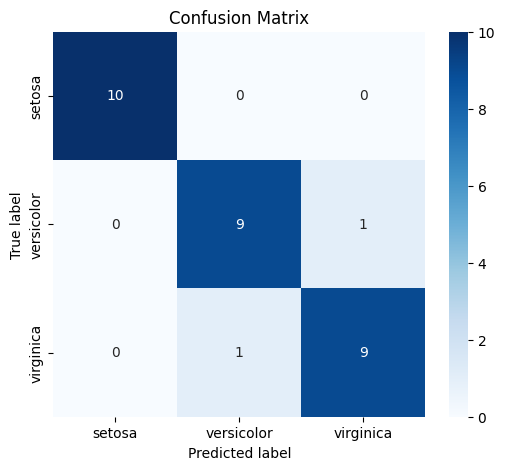

In [199]:
conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=model.classes_, yticklabels=model.classes_)
plt.title('Confusion Matrix')
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()

In [200]:
# ალბათობების გამოთვლა
y_score = model.predict_proba(X_test)

# ბინარიზაცია მრავალკლასიანი ROC/PR გამოთვლისთვის
classes = np.unique(y_test)
y_test_bin = label_binarize(y_test, classes=classes)
n_classes = y_test_bin.shape[1]

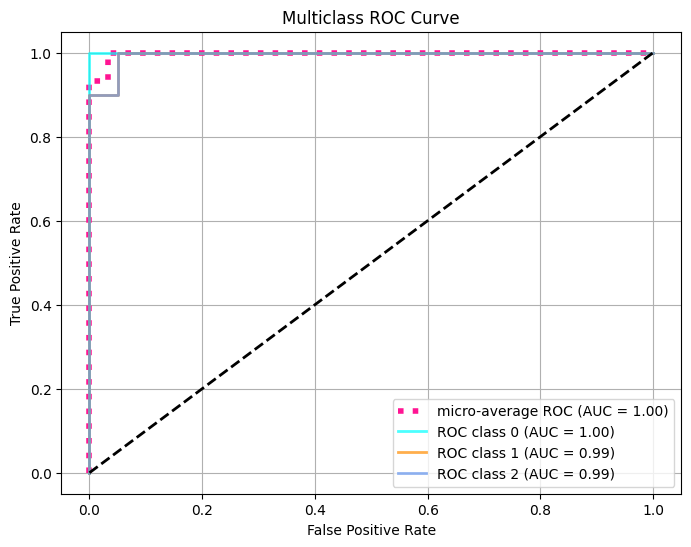

In [258]:
# ROC კერვისა და AUC-ის გამოთვლა თითოეული კლასისთვის
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], thresholds = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# micro-average ROC კერვის გამოთვლა (ყველა კლასის ერთობლივი შეფასება)
fpr["micro"], tpr["micro"], thresholds = roc_curve(y_test_bin.ravel(), y_score.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# ROC კერვის ნახატი
plt.figure(figsize=(8, 6))
plt.plot(fpr["micro"], tpr["micro"],
         label='micro-average ROC (AUC = {0:0.2f})'.format(roc_auc["micro"]),
         color='deeppink', linestyle=':', linewidth=4)

colors = cycle(['aqua', 'darkorange', 'cornflowerblue'])
for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label='ROC class {0} (AUC = {1:0.2f})'.format(i, roc_auc[i]), alpha=0.7)

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multiclass ROC Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

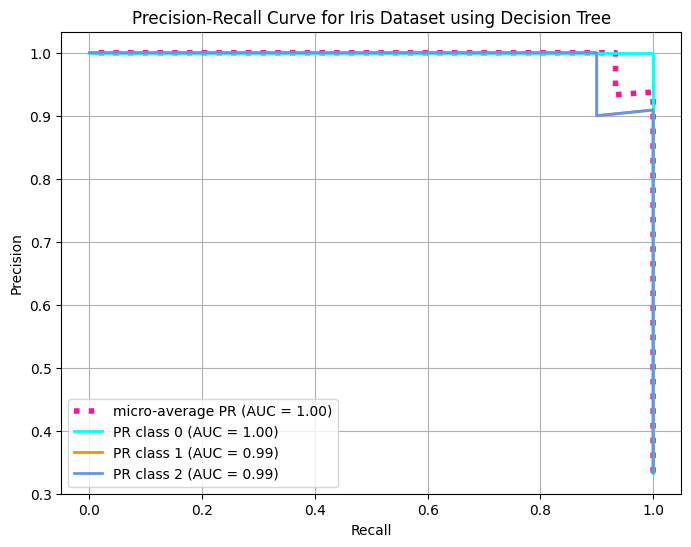

In [157]:
# თითოეული კლასისთვის Precision და Recall-ის გამოთვლა და AUC-ის (average precision) დადგენა
precision = dict()
recall = dict()
pr_auc = dict()

for i in range(n_classes):
    precision[i], recall[i], _ = precision_recall_curve(y_test_bin[:, i], y_score[:, i])
    pr_auc[i] = average_precision_score(y_test_bin[:, i], y_score[:, i])

# micro-average მაჩვენებლის გამოთვლა, სადაც ყველა კლასის მონაცემები ერთად გადაეცემა
precision["micro"], recall["micro"], _ = precision_recall_curve(y_test_bin.ravel(), y_score.ravel())
pr_auc["micro"] = average_precision_score(y_test_bin, y_score, average="micro")

# Plot matplotlib-ის გამოყენებით
plt.figure(figsize=(8, 6))

# micro-average PR კერვა
plt.plot(recall["micro"], precision["micro"],
         label='micro-average PR (AUC = {0:0.2f})'.format(pr_auc["micro"]),
         color='deeppink', linestyle=':', linewidth=4)

# თითოეული კლასის PR კერვები
colors = ['aqua', 'darkorange', 'cornflowerblue']
for i, color in zip(range(n_classes), colors):
    plt.plot(recall[i], precision[i],
             label='PR class {0} (AUC = {1:0.2f})'.format(i, pr_auc[i]),
             color=color, linewidth=2)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve for Iris Dataset using Decision Tree')
plt.legend(loc="lower left")
plt.grid(True)
plt.show()

ევალუაციის მეტრიკები პრობლემის ტიპის მიხედვით:

| პრობლემის ტიპი     | მეტრიკა                                  | აღწერა |
|--------------------|------------------------------------------|---------|
| **რეგრესია**      | Mean Absolute Error (MAE)                   | საშუალო აბსოლუტური შეცდომა|
| **რეგრესია**      | Mean Squared Error (MSE)               | საშუალო კვადრატული შეცდომა |
| **რეგრესია**      | Root Mean Squared Error (RMSE)           | ფესვიანი საშუალო კვადრატული შეცდომა |
| **რეგრესია**      | R-squared (R²)                           | რამდენად კარგად ხსნის მოდელი მონაცემთა ვარიაციას |
| **კლასიფიკაცია**  | Accuracy                                 | რამდენად სწორია მოდელი |
| **კლასიფიკაცია**  | Precision                                | რამდენად ზუსტია დადებითი პროგნოზები |
| **კლასიფიკაცია**  | Recall                                   | რამდენი რეალური დადებითი შემთხვევა სწორად გამოვიცანით|
| **კლასიფიკაცია**  | F1-score                                 | Precision და Recall-ის ჰარმონიული საშუალო |